In [1]:
import sys
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

ROOT = Path("../../")
sys.path.insert(0, str(ROOT))

from src.fetch.yt_api import get_channel_video_ids, get_videos_metadata, Video

In [ ]:
parties_df = pd.read_csv(ROOT / "data/sourcing/party_channels.csv", sep=";")
parties_df.head()

,channel,url,id,ches_galtan,ches_economic,ches_lrgen,Party
0,LiberalAlliance,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA
1,Socialdemokratiet,https://www.youtube.com/@socialdemokraterne,UCT6gfYobgf7pQBBVljPNDLw,4.00,4.09,4.00,S
2,Venstre,https://www.youtube.com/@venstredk,UCyiIC6sYmRMHXNaumJpSHow,4.64,6.55,6.64,V
3,Moderaterne,https://www.youtube.com/@Moderaterne2025,UC6qZQJQfju2e16C6UhtueXA,3.82,5.64,5.55,M
4,SocialistiskFolkeparti,https://www.youtube.com/@sfpolitik,UC88qNpEHMhO9JMGapSik7zQ,3.00,2.73,2.73,SF


In [49]:
parties_df["galtan_ideology"] = pd.cut(parties_df["ches_galtan"], bins=3, labels=["left", "center", "right"])
parties_df["economic_ideology"] = pd.cut(parties_df["ches_economic"], bins=3, labels=["left", "center", "right"])
parties_df["ideology"] = pd.cut(parties_df["ches_lrgen"], bins=3, labels=["left", "center", "right"])

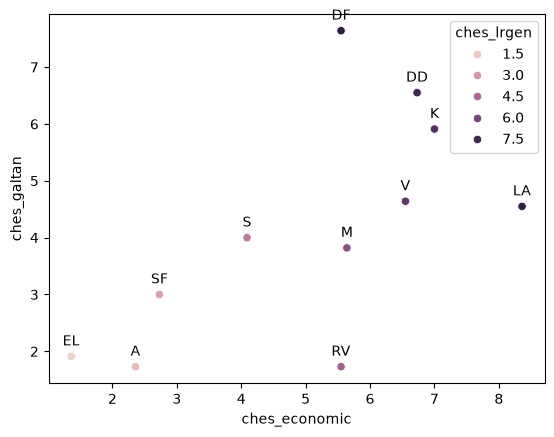

In [ ]:
ax = sns.scatterplot(data=parties_df, y="ches_galtan", x="ches_economic", hue="ideololgy")

# Iterate and annotate
for idx, row in parties_df.iterrows():
    ax.annotate(
        row['Party'],
        (row['ches_economic'], row['ches_galtan']),
        textcoords="offset points",
        xytext=(0, 8), # Offset vertically by 8 pixels
        ha='center',
        fontsize=10
    )

plt.show()

In [29]:
video_ids = []

for idx, row in parties_df.iterrows():
    vids : list[Video] = get_channel_video_ids(row["id"])
    for vid in tqdm(vids):
        video_ids.append({"channel": row["channel"], "video_id": vid.id})

video_df = pd.DataFrame(video_ids)

100%|██████████| 441/441 [00:00<00:00, 348274.91it/s]


In [8]:
video_df.head()

,channel,video_id
0,LiberalAlliance,UAvxR663YGw
1,LiberalAlliance,WTJ-MnqwXPw
2,LiberalAlliance,20BttTpXVFg
3,LiberalAlliance,C5kvvChHCxQ
4,LiberalAlliance,mAxNJ4YpvxA


In [9]:
video_metadata = []

video_list = video_df["video_id"].to_list()
video_list = [Video(id=vid) for vid in video_list]
chunks = [video_list[i:i + 50] for i in range(0, len(video_list), 50)]

for chunk in tqdm(chunks):
    vids = get_videos_metadata(chunk)
    for vid in vids:
        video_metadata.append({
            "video_id": vid.id,
            "channel": vid.channel,
            "title": vid.title,
            "description": vid.description,
            "tags": vid.tags,
            "category": vid.category
        })

video_metadata_df = pd.DataFrame(video_metadata)

  0%|          | 0/77 [00:00<?, ?it/s]

100%|██████████| 77/77 [00:24<00:00,  3.14it/s]


In [38]:
video_metadata_df.tail()

,video_id,channel,title,description,tags,category,url,id,ches_galtan,ches_economic,ches_lrgen,Party
3798,hcfVM8vVc68,Alternativet,Alternativet sommerhilsen fra Rasmus Bahnsen,,"[Rasmus Bahnsen, Alternativet, Bæredygtig, Som...",22,https://www.youtube.com/@alternativet_,UChrtZHYBEo0M8Qj_OiAOCIQ,1.73,2.36,2.0,A
3799,hdL1oeFL7bc,Alternativet,Alternativet sommerhilsen fra Maja Krog,Skriv under her: http://alternativet.dk/skriv-...,"[Alternativet, Maja Krogh, Sommer, Vælgererklæ...",22,https://www.youtube.com/@alternativet_,UChrtZHYBEo0M8Qj_OiAOCIQ,1.73,2.36,2.0,A
3800,p1YZaKDdhB8,Alternativet,Alternativet sommerhilsen fra Mikkel Nørskov Kjær,,"[Alternativet, Mikkel Nørskov Kjær, Sommer, Væ...",22,https://www.youtube.com/@alternativet_,UChrtZHYBEo0M8Qj_OiAOCIQ,1.73,2.36,2.0,A
3801,EzVBu8GJyHU,Alternativet,Alternativet sommerhilsen fra Richard Georg En...,,"[Alternativet, Richard Georg Engström, Sommer,...",22,https://www.youtube.com/@alternativet_,UChrtZHYBEo0M8Qj_OiAOCIQ,1.73,2.36,2.0,A
3802,8Ppss7xUh14,Alternativet,Alternativet sommerhilsen fra Mads Ringblom,,"[Alternativet, Mads Ringblom, Vælgererklæring,...",22,https://www.youtube.com/@alternativet_,UChrtZHYBEo0M8Qj_OiAOCIQ,1.73,2.36,2.0,A


In [20]:
video_metadata_df = video_metadata_df.merge(parties_df, on="channel", how="left")

In [21]:
video_metadata_df.head()

,video_id,channel,title,description,tags,category,url,id,ches_galtan,ches_economic,ches_lrgen,Party
0,UAvxR663YGw,LiberalAlliance,Har Mette forstået det rigtigt?,Atomkraft? Ja tak!,[],25,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA
1,WTJ-MnqwXPw,LiberalAlliance,Drop skræmmekampagnen mod kernekraft,Drop skræmmekampagnerne og den forældede modst...,[],25,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA
2,20BttTpXVFg,LiberalAlliance,Danskerne fortjener den bedste behandling,LA vil give dig adgang til den nyeste og bedst...,[],25,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA
3,C5kvvChHCxQ,LiberalAlliance,Kan Mette mon vælge?,Det er heller ikke nemt.,[],25,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA
4,mAxNJ4YpvxA,LiberalAlliance,Skattesystemet,"Skattesystemet er blevet så kompliceret, at in...",[],25,https://www.youtube.com/@liberaldk,UCOoY_0tkXsIXuZT-56NVXBg,4.55,8.36,7.82,LA


In [39]:
video_metadata_df.to_csv(ROOT / "data/sourcing/out/parties_videos.csv")